# CS336 · Colab GPU 测速与训练

这份 Notebook 复用项目中的 train.py。先用相同工作负载比较 GPU，再选择正式训练所用的卡。

## 今天应该运行哪些部分？

| 你的目的 | 执行路线 |
|---|---|
| 第一次上传项目并测速 | 第 1 节全部 → 第 2 节检查 → 第 3 节 |
| 从 L4 换成 A100 / 其他 GPU 后继续测速 | 第 1 节，**跳过 1.3 上传** → 第 3 节 |
| 选择好 GPU，开始一个新实验 | 第 1 节 → 第 2 节 → 第 4 节 |
| 断线或换运行时后恢复已有训练 | 第 1 节，**跳过 1.3** → 第 5 节 |
| 只用已有 checkpoint 生成文本 | 第 1 节，**跳过 1.3** → 第 6 节 |
| 重新汇总已有 GPU 测速结果 | 第 1 节，**跳过 1.3** → 3.1 → 3.3 |

**按目的选择分支，不要直接“全部运行”。** 第 4 节会启动 40,000 步训练；第 5 节是恢复分支，不能接着第 4 节重复执行。

## 更换 kernel / GPU 后，哪些东西会消失？

| 变化 | 变量、函数、显存中的模型 | /content 本地文件 | Google Drive 中已保存的文件 |
|---|---|---|---|
| 仅刷新页面，仍连接同一运行时 | 通常保留 | 保留 | 保留 |
| 仅重启 Python kernel | 清空，需要重跑定义和导入 | 同一虚拟机上通常保留 | 保留 |
| 更换 GPU、删除运行时、获得新虚拟机 | 清空 | 应按已丢失处理，需要重新复制 | 保留 |

统一做法：**重新执行第 1 节，跳过首次上传，然后进入需要的分支。**
无需重新分词，也无需从头训练：项目包、token 数据、测速表、checkpoint 都从 Drive 恢复。
1.1 会检查/补齐依赖；同一环境已安装的包不会因为没有 -U 而被主动整体升级。

资料：[Colab 运行时与文件说明](https://research.google.com/colaboratory/faq.html)。

## 本地准备 · 首次上传前做一次

先等 prepare_data.py 输出 train.npy 和 val.npy 两条 Saved。下面命令在 **本机 Git Bash** 中执行，不是 Colab 代码格。

~~~bash
cd /d/CourseLearning/cs336-from-scratch
uv run python -m zipfile -c cs336_colab.zip   cs336_basics tests pyproject.toml README.md   outputs/tokenizer-debug-10k   data/tokenized/train.npy data/tokenized/val.npy
~~~

压缩包根目录应包含 cs336_basics/、tests/、tokenizer-debug-10k/、train.npy、val.npy。
准备数据和打包只做一次；代码或数据更新后才重新打包上传。

# 1 · 每次新运行时的公共准备

## 1.1 安装依赖并检查 GPU

先在 Colab 的“运行时 → 更改运行时类型”选择 GPU。
这里保留 Colab 自带的 CUDA PyTorch，只补当前代码需要的依赖；后续统一使用当前 Python，不另建 uv 环境。
应看到 CUDA available: True，并成功执行一次矩阵乘法。

In [1]:
%pip install -q numpy pandas "einops>=0.8" regex tqdm jaxtyping pytest pytest-timeout tiktoken

import csv
import json
import os
import re
import shutil
import subprocess
import sys
import time
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "请先切换到 GPU 运行时"

subprocess.run(
    [
        "nvidia-smi",
        "--query-gpu=name,memory.total,driver_version",
        "--format=csv,noheader",
    ],
    check=True,
)

x = torch.randn(256, 256, device="cuda:0")
print("CUDA matrix multiplication:", (x @ x).mean().item())
del x

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA build: 13.0
CUDA available: True
CUDA matrix multiplication: 0.01393989659845829


## 1.2 挂载 Drive，设置路径与实验名

RUN_NAME 是正式训练/恢复/生成共用的实验名。**新实验换名字；继续已有实验保持原名。**
GPU 测速使用单独的 benchmarks 目录，不会覆盖正式训练的 checkpoint。

In [2]:
from google.colab import drive

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/cs336")
PROJECT = Path("/content/cs336")
RUN_NAME = "tinystories_baseline_01"

DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

print("持久化目录:", DRIVE_ROOT)
print("本次运行的项目目录:", PROJECT)
print("正式实验名:", RUN_NAME)

Mounted at /content/drive
持久化目录: /content/drive/MyDrive/cs336
本次运行的项目目录: /content/cs336
正式实验名: tinystories_baseline_01


## 1.3 首次上传或更新项目包 · 换 GPU 时跳过

只选择本机的 cs336_colab.zip。它会备份到 Drive，供后续运行时恢复。
如果 Drive 中已有本次使用的压缩包，直接执行 1.4。

In [3]:
from google.colab import files

os.chdir("/content")
uploaded = files.upload()
uploaded_name = next(iter(uploaded))

shutil.copy2(
    Path("/content") / uploaded_name,
    DRIVE_ROOT / "cs336_colab.zip",
)
del uploaded

print("压缩包已保存到:", DRIVE_ROOT / "cs336_colab.zip")

KeyboardInterrupt: 

## 1.4 从 Drive 恢复项目和 token 数据

每次换 GPU 后重跑。这里只复制并解压已有数据，不会重新分词。
训练从 /content 读数据，checkpoint 和日志写入 Drive。

In [3]:
import zipfile
import numpy as np

local_zip = Path("/content/cs336_colab.zip")

shutil.copy2(DRIVE_ROOT / "cs336_colab.zip", local_zip)

PROJECT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(local_zip) as archive:
    archive.extractall(PROJECT)

os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT))

for split in ("train", "val"):
    data = np.load(PROJECT / f"{split}.npy", mmap_mode="r")
    print(
        f"{split}: shape={data.shape}, dtype={data.dtype}, "
        f"first_tokens={data[:10].tolist()}"
    )
    assert data.ndim == 1
    assert data.dtype == np.uint16
    del data

train: shape=(42329136,), dtype=uint16, first_tokens=[10, 425, 436, 259, 395, 399, 281, 259, 389, 494]
val: shape=(5473731,), dtype=uint16, first_tokens=[117, 881, 489, 498, 266, 328, 618, 372, 263, 937]


## 1.5 定义训练启动工具 · 只定义函数，不开始训练

所有训练都调用已有的 train.py。每条日志带本次会话的 elapsed_s；恢复训练会开始新的计时段。
子进程结束时还会报告 PyTorch 的峰值分配/保留显存，供第 3 节比较。
使用 FP32 参数和 high 矩阵乘法精度；此设置允许 CUDA 上的 TF32 等加速路径。

资料：[PyTorch 矩阵乘法精度](https://docs.pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html)。

In [4]:
import time


def run_training(config, log_path):
    entry = (
        "import torch; "
        "torch.set_float32_matmul_precision('high'); "
        "from cs336_basics.train import main; main(); "
        "print("
        "f'peak_allocated_gib={torch.cuda.max_memory_allocated() / 2**30:.6f} '"
        "f'peak_reserved_gib={torch.cuda.max_memory_reserved() / 2**30:.6f}'"
        ")"
    )

    command = [sys.executable, "-u", "-c", entry]

    for name, value in config.items():
        command.append("--" + name)
        values = value if isinstance(value, list) else [value]
        command.extend(str(item) for item in values)

    started = time.perf_counter()

    with log_path.open("a", encoding="utf-8") as log:
        log.write("\n--- new training session ---\n")
        log.flush()

        process = subprocess.Popen(
            command,
            cwd=PROJECT,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
        )

        try:
            for line in process.stdout:
                elapsed = time.perf_counter() - started
                record = f"elapsed_s={elapsed:.3f} {line}"

                print(record, end="", flush=True)
                log.write(record)
                log.flush()

            return_code = process.wait()
        finally:
            # 点击停止时，也停止训练子进程。
            if process.poll() is None:
                process.terminate()
                process.wait()
            process.stdout.close()

    if return_code != 0:
        raise subprocess.CalledProcessError(return_code, command)

## 1.6 统一模型与训练配置

比较不同 GPU 时，保持此配置、项目包、数据和数值精度一致。
默认正式预算：32 × 256 × 40000 = 327,680,000 tokens。

第 3 节只复制这份配置运行 300 步测速，不会修改正式训练步数。
显存不足时可以降低 batch-size，但**所有待比较 GPU 都要用新的相同 batch-size 重新测一次**。

In [5]:
BASE_CONFIG = {
    "train-data": str(PROJECT / "train.npy"),
    "val-data": str(PROJECT / "val.npy"),
    "device": "cuda:0",
    "seed": 42,

    "vocab-size": 10000,
    "context-length": 256,
    "d-model": 512,
    "num-layers": 4,
    "num-heads": 16,
    "d-ff": 1344,
    "rope-theta": 10000.0,

    "batch-size": 32,
    "max-steps": 40000,
    "max-lr": 1e-3,
    "min-lr": 1e-4,
    "warmup-steps": 1000,
    "cosine-steps": 40000,
    "betas": [0.9, 0.95],
    "eps": 1e-8,
    "weight-decay": 0.1,
    "grad-clip": 1.0,

    "log-every": 10,
    "eval-every": 500,
    "eval-batches": 20,
    "save-every": 500,
}

# 2 · 首次运行或代码更新后的检查

## 2.1 组件测试

预计得到 2 passed。换 GPU、代码未变时可跳过整个第 2 节。

In [7]:
subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/test_data.py::test_get_batch",
        "tests/test_serialization.py::test_checkpointing",
        "--basetemp=/content/cs336_pytest",
        "-q",
    ],
    cwd=PROJECT,
    check=True,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', 'tests/test_data.py::test_get_batch', 'tests/test_serialization.py::test_checkpointing', '--basetemp=/content/cs336_pytest', '-q'], returncode=0)

## 2.2 20 步完整训练检查

检查前向、反向、验证和 checkpoint。这里只用于确认流程，不能用 20 步的 loss 判断最终收敛。
smoke.pt 保存在本地目录，不会覆盖正式实验。

In [8]:
smoke_config = {
    **BASE_CONFIG,
    "checkpoint": str(PROJECT / "smoke.pt"),
    "max-steps": 20,
    "warmup-steps": 2,
    "cosine-steps": 20,
    "log-every": 5,
    "eval-every": 20,
    "eval-batches": 2,
    "save-every": 20,
}

run_training(smoke_config, PROJECT / "smoke.log")

state = torch.load(
    PROJECT / "smoke.pt",
    map_location="cpu",
    weights_only=True,
)

assert state["iteration"] == 20
assert all(
    torch.isfinite(value).all().item()
    for value in state["model"].values()
)

print("GPU 短训练通过，checkpoint 中的参数均为有限值。")
del state

elapsed_s=4.673 step=5 train_loss=7.5590 lr=0.000972862
elapsed_s=5.796 step=10 train_loss=5.8823 lr=0.000703909
elapsed_s=6.917 step=15 train_loss=5.2717 lr=0.000325
elapsed_s=8.037 step=20 train_loss=5.0078 lr=0.000106837
elapsed_s=8.179 step=20 val_loss=4.9441
elapsed_s=8.484 Saved checkpoint: /content/cs336/smoke.pt
elapsed_s=8.487 peak_allocated_gib=3.991599 peak_reserved_gib=4.248047
GPU 短训练通过，checkpoint 中的参数均为有限值。


# 3 · 对比 GPU 的速度、显存和额度消耗

## 3.1 测速设置 · 每换一张卡，只更新额度消耗率

在 Colab 资源面板查看本次运行时的 **计算单位/小时**，填入 CU_PER_HOUR。
未知时保留 None：仍记录速度与显存，但不会把未知费率当成免费。
不同卡可能有不同费率，需要分别填写。

固定前 50 步预热，再计时 250 步。它们是 GPU 测速预热，与 BASE_CONFIG 中的学习率 warmup-steps 不同。
BENCHMARK_GROUP 用于区分不同代码/数据版本；更新项目包或数据后改成一个新名字。

In [11]:
BENCHMARK_GROUP = "tinystories_fp32_v1"
BENCHMARK_WARMUP_STEPS = 50
BENCHMARK_MEASURE_STEPS = 250
CU_PER_HOUR = 1.94  # 例如面板显示 4.5 单位/小时，就填 4.5；不要猜费率。

BENCHMARK_DIR = DRIVE_ROOT / "benchmarks"
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)
BENCHMARK_CSV = BENCHMARK_DIR / "gpu_results.csv"

## 3.2 在当前 GPU 上测速，并保存记录

使用与正式训练相同的模型、data loader、优化器和学习率调度，每次从相同随机种子开始。
以第 50 步和第 300 步的训练日志时间差计时，包含取 batch、搬运数据、前向、反向、裁剪和更新。
日志打印中的 loss.item() 会同步 CUDA；前 50 步的初始化/预热时间不计入吞吐。

测速区间没有验证或 checkpoint 写入。最后一次验证和保存发生在第 300 步训练日志之后，
因此不计入耗时；**显存峰值则覆盖整个子进程，包括最后的验证**。
PyTorch allocated/reserved 不包含驱动和其他进程的全部显存。

只运行本格会消耗约 300 步训练的额度。换卡前等到 CSV 保存成功；
然后更换 GPU → 重跑第 1 节（跳过 1.3）→ 3.1 → 本格 → 3.3。
不要在另一个训练进程仍运行时测速。

In [12]:
timestamp = datetime.now(timezone(timedelta(hours=8)))
stamp = timestamp.strftime("%Y%m%d_%H%M%S_%f")
benchmark_log = BENCHMARK_DIR / f"{stamp}.log"
total_steps = BENCHMARK_WARMUP_STEPS + BENCHMARK_MEASURE_STEPS

benchmark_config = {
    **BASE_CONFIG,
    "checkpoint": str(PROJECT / "benchmark.pt"),
    "max-steps": total_steps,
    "log-every": BENCHMARK_WARMUP_STEPS,
    "eval-every": total_steps,
    "eval-batches": 2,
    "save-every": total_steps,
}

run_training(benchmark_config, benchmark_log)

text = benchmark_log.read_text(encoding="utf-8")
training_rows = re.findall(
    r"elapsed_s=([0-9.]+)\s+step=(\d+)\s+train_loss=([^\s]+)",
    text,
)
step_times = {int(step): float(seconds) for seconds, step, _ in training_rows}
elapsed = step_times[total_steps] - step_times[BENCHMARK_WARMUP_STEPS]
seconds_per_step = elapsed / BENCHMARK_MEASURE_STEPS
tokens_per_step = BASE_CONFIG["batch-size"] * BASE_CONFIG["context-length"]
tokens_per_s = tokens_per_step / seconds_per_step

memory = re.search(
    r"peak_allocated_gib=([0-9.]+)\s+peak_reserved_gib=([0-9.]+)",
    text,
)
final_train_loss = float(training_rows[-1][2])
assert np.isfinite(final_train_loss), "测速发生数值异常，先检查训练日志。"

result = {
    "timestamp": timestamp.isoformat(timespec="seconds"),
    "benchmark_group": BENCHMARK_GROUP,
    "gpu": torch.cuda.get_device_name(0),
    "torch_version": str(torch.__version__),
    "cuda_version": torch.version.cuda,
    "matmul_precision": "high",
    "warmup_steps": BENCHMARK_WARMUP_STEPS,
    "measured_steps": BENCHMARK_MEASURE_STEPS,
    "step_ms": seconds_per_step * 1000,
    "tokens_per_s": tokens_per_s,
    "peak_allocated_gib": float(memory.group(1)),
    "peak_reserved_gib": float(memory.group(2)),
    "train_only_hours": BASE_CONFIG["max-steps"] * seconds_per_step / 3600,
    "cu_per_hour": CU_PER_HOUR,
    "cu_per_million_tokens": (
        None if CU_PER_HOUR is None
        else CU_PER_HOUR * 1_000_000 / (3600 * tokens_per_s)
    ),
    "final_train_loss": final_train_loss,
    "config_json": json.dumps(BASE_CONFIG, sort_keys=True),
    "log_file": str(benchmark_log),
}

with BENCHMARK_CSV.open("a", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(result))
    if stream.tell() == 0:
        writer.writeheader()
    writer.writerow(result)

display(pd.DataFrame([result])[[
    "gpu", "step_ms", "tokens_per_s", "peak_allocated_gib",
    "peak_reserved_gib", "train_only_hours", "cu_per_hour",
    "cu_per_million_tokens",
]].round(3))
print("测速记录已保存:", BENCHMARK_CSV)

elapsed_s=14.344 step=50 train_loss=8.0039 lr=4.9e-05
elapsed_s=25.580 step=100 train_loss=5.9208 lr=9.9e-05
elapsed_s=36.812 step=150 train_loss=4.7509 lr=0.000149
elapsed_s=48.044 step=200 train_loss=3.9012 lr=0.000199
elapsed_s=59.284 step=250 train_loss=3.5785 lr=0.000249
elapsed_s=70.531 step=300 train_loss=3.5314 lr=0.000299
elapsed_s=70.673 step=300 val_loss=3.2177
elapsed_s=71.160 Saved checkpoint: /content/cs336/benchmark.pt
elapsed_s=71.165 peak_allocated_gib=3.991599 peak_reserved_gib=4.248047


,gpu,step_ms,tokens_per_s,peak_allocated_gib,peak_reserved_gib,train_only_hours,cu_per_hour,cu_per_million_tokens
0,NVIDIA L4,224.748,36449.713,3.992,4.248,2.497,1.94,0.015


测速记录已保存: /content/drive/MyDrive/cs336/benchmarks/gpu_results.csv


## 3.3 汇总所有已测 GPU

只汇总与当前训练配置、测速步数、精度和 BENCHMARK_GROUP 相同的记录。
同一 GPU/环境/费率重复测速时，速度与成本取中位数，显存取最大值。

- **tokens_per_s 越大越快**。
- **cu_per_million_tokens 越小越省额度**；空白表示费率未知。
- **train_only_hours** 是完成当前正式步数的训练计算时间估计，不含准备、验证和 checkpoint 保存。
- **peak_allocated_gib** 是 PyTorch 张量峰值；reserved 是分配器保留显存，通常更大。
- 不同 torch/cuda 版本分开显示；版本不同时，比较的是整个 Colab 环境，而非纯硬件差异。

建议每张卡测两次。先确认 batch 能装下，再在可接受的时间内选择单位 token 成本较低的卡。

In [ ]:
records = pd.read_csv(BENCHMARK_CSV)
same = records.loc[
    records["benchmark_group"].eq(BENCHMARK_GROUP)
    & records["config_json"].eq(json.dumps(BASE_CONFIG, sort_keys=True))
    & records["matmul_precision"].eq("high")
    & records["warmup_steps"].eq(BENCHMARK_WARMUP_STEPS)
    & records["measured_steps"].eq(BENCHMARK_MEASURE_STEPS)
].copy()

summary = (
    same.groupby(
        ["gpu", "torch_version", "cuda_version", "cu_per_hour"],
        dropna=False,
    )
    .agg(
        runs=("tokens_per_s", "size"),
        step_ms=("step_ms", "median"),
        tokens_per_s=("tokens_per_s", "median"),
        peak_allocated_gib=("peak_allocated_gib", "max"),
        peak_reserved_gib=("peak_reserved_gib", "max"),
        train_only_hours=("train_only_hours", "median"),
        cu_per_million_tokens=("cu_per_million_tokens", "median"),
    )
    .reset_index()
)

print("速度排名（每秒 token 数从高到低）")
display(summary.sort_values("tokens_per_s", ascending=False).round(3))

priced = summary.dropna(subset=["cu_per_million_tokens"])
if not priced.empty:
    print("额度效率排名（每百万 token 所需单位数从低到高）")
    display(priced.sort_values("cu_per_million_tokens").round(3))
else:
    print("尚无已填写费率的记录；在 3.1 填 CU_PER_HOUR 后重新测速即可。")

# 4 · 新建正式训练实验

**本格会启动 BASE_CONFIG 中指定的完整训练预算，默认 40,000 步。**
先在 1.2 设置一个未使用过的 RUN_NAME。新实验从头训练，不加载测速或 smoke 的 checkpoint。
同名目录已存在时，如要继续训练，请执行第 5 节；如要做另一组实验，请换 RUN_NAME。

配置、环境、日志和 latest.pt 都保存到 Drive。默认每 500 步保存，最后一步也保存。
latest.pt 每次更新为最近一次状态；保留的内容包括模型参数、优化器状态和已完成步数。

In [6]:
import json

RUN_DIR = DRIVE_ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True)  # 同名目录存在时停止，避免覆盖已有实验。

config = {
    **BASE_CONFIG,
    "checkpoint": str(RUN_DIR / "latest.pt"),
}

(RUN_DIR / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

environment = {
    "python": sys.version,
    "torch": torch.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "numpy": np.__version__,
    "float32_matmul_precision": "high",
}

(RUN_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2),
    encoding="utf-8",
)

print("实验目录:", RUN_DIR)
run_training(config, RUN_DIR / "train.log")

实验目录: /content/drive/MyDrive/cs336/runs/tinystories_baseline_01
elapsed_s=10.175 step=10 train_loss=9.2074 lr=9e-06
elapsed_s=12.413 step=20 train_loss=9.0488 lr=1.9e-05
elapsed_s=14.650 step=30 train_loss=8.7869 lr=2.9e-05
elapsed_s=16.888 step=40 train_loss=8.4274 lr=3.9e-05
elapsed_s=19.126 step=50 train_loss=8.0039 lr=4.9e-05
elapsed_s=21.364 step=60 train_loss=7.6299 lr=5.9e-05
elapsed_s=23.602 step=70 train_loss=7.2524 lr=6.9e-05
elapsed_s=25.840 step=80 train_loss=6.7523 lr=7.9e-05
elapsed_s=28.081 step=90 train_loss=6.3253 lr=8.9e-05
elapsed_s=30.319 step=100 train_loss=5.9208 lr=9.9e-05
elapsed_s=32.558 step=110 train_loss=5.5550 lr=0.000109
elapsed_s=34.795 step=120 train_loss=5.1738 lr=0.000119
elapsed_s=37.029 step=130 train_loss=4.9764 lr=0.000129
elapsed_s=39.263 step=140 train_loss=4.6920 lr=0.000139
elapsed_s=41.498 step=150 train_loss=4.7509 lr=0.000149
elapsed_s=43.734 step=160 train_loss=4.3613 lr=0.000159
elapsed_s=45.970 step=170 train_loss=4.1782 lr=0.000169
elaps

KeyboardInterrupt: 

# 5 · 恢复已有训练 · 不执行第 4 节

换 GPU/运行时后，先执行第 1 节（跳过 1.3），在 1.2 填回原实验的 RUN_NAME。
本格读取 Drive 中保存的配置，恢复模型和优化器，从已保存的步数继续。

例如已保存 8,000 步，目标 40,000 步，则继续剩余 32,000 步。
只重启 Python kernel 也需要重跑函数/变量定义，但不需要重新训练已保存的部分。
恢复的随机采样序列不保证与未中断时完全一致，因为当前 checkpoint 没有保存随机数状态。

In [6]:
import json

RUN_DIR = DRIVE_ROOT / "runs" / RUN_NAME

config = json.loads(
    (RUN_DIR / "config.json").read_text(encoding="utf-8")
)

resume_config = {
    **config,
    "resume": config["checkpoint"],
}

run_training(resume_config, RUN_DIR / "resume.log")

elapsed_s=16.152 Resumed after 21500 completed steps
elapsed_s=18.813 step=21510 train_loss=1.4758 lr=0.000513465
elapsed_s=21.049 step=21520 train_loss=1.4942 lr=0.000513104
elapsed_s=23.285 step=21530 train_loss=1.4413 lr=0.000512742
elapsed_s=25.519 step=21540 train_loss=1.4252 lr=0.000512381
elapsed_s=27.753 step=21550 train_loss=1.4295 lr=0.00051202
elapsed_s=29.986 step=21560 train_loss=1.4640 lr=0.000511659
elapsed_s=32.221 step=21570 train_loss=1.5033 lr=0.000511298
elapsed_s=34.457 step=21580 train_loss=1.4196 lr=0.000510936
elapsed_s=36.693 step=21590 train_loss=1.4543 lr=0.000510575
elapsed_s=38.928 step=21600 train_loss=1.4826 lr=0.000510214
elapsed_s=41.164 step=21610 train_loss=1.3874 lr=0.000509853
elapsed_s=43.402 step=21620 train_loss=1.3994 lr=0.000509492
elapsed_s=45.638 step=21630 train_loss=1.4341 lr=0.000509131
elapsed_s=47.874 step=21640 train_loss=1.5003 lr=0.00050877
elapsed_s=50.111 step=21650 train_loss=1.5440 lr=0.000508409
elapsed_s=52.349 step=21660 train_

# 6 · 使用已有 checkpoint 生成文本

执行第 1 节并设置 RUN_NAME 后，可以直接执行本格；不依赖本次是否运行过第 4/5 节。
生成结果保存为该实验目录下的 sample.txt。

In [7]:
RUN_DIR = DRIVE_ROOT / "runs" / RUN_NAME
config = json.loads(
    (RUN_DIR / "config.json").read_text(encoding="utf-8")
)

from cs336_basics.transformer import TransformerLM
from cs336_basics.tokenizer import Tokenizer
from cs336_basics.generate import generate

torch.set_float32_matmul_precision("high")

tokenizer = Tokenizer.from_files(
    PROJECT / "tokenizer-debug-10k" / "vocab.json",
    PROJECT / "tokenizer-debug-10k" / "merges.txt",
    special_tokens=["<|endoftext|>"],
)

model = TransformerLM(
    vocab_size=config["vocab-size"],
    context_length=config["context-length"],
    num_layers=config["num-layers"],
    d_model=config["d-model"],
    num_heads=config["num-heads"],
    d_ff=config["d-ff"],
    rope=True,
    max_seq_len=config["context-length"],
    theta=config["rope-theta"],
    device="cuda:0",
    dtype=torch.float32,
)

checkpoint = torch.load(
    config["checkpoint"],
    map_location="cpu",
    weights_only=True,
)

model.load_state_dict(checkpoint["model"])
print("Checkpoint step:", checkpoint["iteration"])
del checkpoint

prompt = "Once upon a time"
eos_id = tokenizer.byte_to_id[b"<|endoftext|>"]

output_ids = generate(
    model=model,
    prompt_ids=tokenizer.encode(prompt),
    context_length=config["context-length"],
    eos_token_id=eos_id,
    max_new_tokens=256,
    temperature=0.8,
    top_p=0.9,
)

if output_ids[-1] == eos_id:
    output_ids = output_ids[:-1]

generated_text = tokenizer.decode(output_ids)
print(generated_text)

(RUN_DIR / "sample.txt").write_text(
    generated_text,
    encoding="utf-8",
)
# 释放 Notebook 进程里的模型，给后续训练子进程留出显存。
del model
torch.cuda.empty_cache()

Checkpoint step: 40000
Once upon a time, there was a little girl named Sue. Sue loved to dress up in her mom's clothes. One day, Sue's mom told her, "I have to go to the store. Can you help me?" Sue said, "Yes, mom!"
At the store, Sue and her mom found the best dress. It was a pretty pink dress with big flowers. Sue was so happy. She said, "Thank you, mom!" Her mom was happy too. They bought the dress and went home.
When they got home, Sue put on the dress. It fit her perfectly. Her mom was very proud of her. Sue said, "Mom, you are the best at mom's dress!" Sue's mom smiled and said, "You did a great job, Sue! I'm so proud of you!"
Sue wore her new dress all day. She felt happy and loved. From that day on, Sue and her mom would always walk to the store together.



# 7 · 下载本地副本 · 可选

结果已经在 Google Drive 中，不下载也能在下次运行时恢复。
每次训练、测试和测速结束后，不再使用 GPU 时可断开并删除运行时。

## 保存位置

| 文件 | Drive 路径 |
|---|---|
| 项目与数据包 | MyDrive/cs336/cs336_colab.zip |
| 各 GPU 的测速记录 | MyDrive/cs336/benchmarks/gpu_results.csv |
| 每次测速原始日志 | MyDrive/cs336/benchmarks/时间戳.log |
| 正式实验配置、日志、checkpoint | MyDrive/cs336/runs/RUN_NAME/ |

下载前先确认 1.2 中的 RUN_NAME 是需要的实验名。

In [8]:
RUN_DIR = DRIVE_ROOT / "runs" / RUN_NAME

from google.colab import files

files.download(str(RUN_DIR / "latest.pt"))
files.download(str(RUN_DIR / "config.json"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


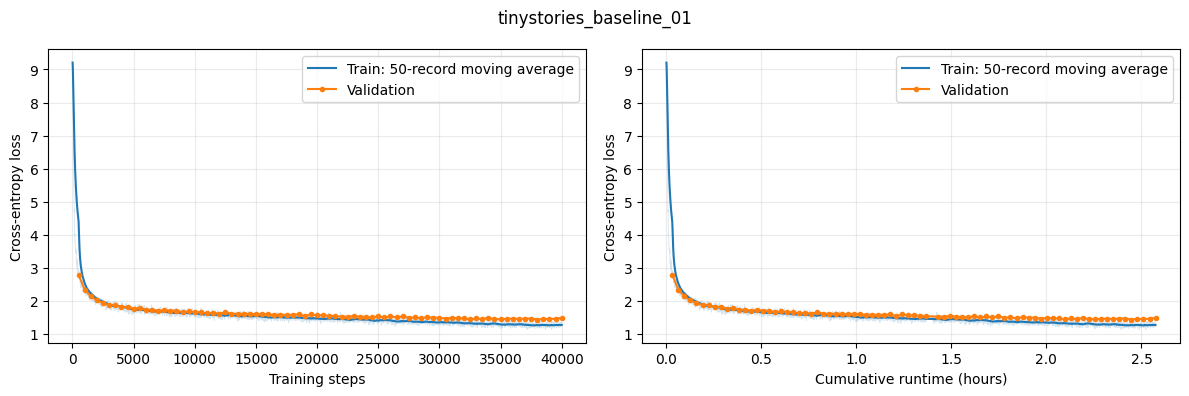

最后一次验证 loss: 1.4799
最低验证 loss: 1.4337
结果保存到: /content/drive/MyDrive/cs336/runs/tinystories_baseline_01


In [9]:
from pathlib import Path
import json
import re

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")

RUNS = Path("/content/drive/MyDrive/cs336/runs")
EXPERIMENT = "tinystories_baseline_01"
run_dir = RUNS / EXPERIMENT


def read_curves(run_dir):
    rows = []
    offset = 0.0

    for name in ("train.log", "resume.log"):
        path = run_dir / name
        if not path.exists():
            continue

        last_time = 0.0

        for line in path.read_text(encoding="utf-8").splitlines():
            # 同一个文件也可能包含多次恢复训练。
            if line.strip() == "--- new training session ---":
                offset += last_time
                last_time = 0.0
                continue

            time_match = re.search(r"elapsed_s=([\d.]+)", line)
            if not time_match:
                continue

            last_time = float(time_match[1])
            metric = re.search(
                r"step=(\d+) (train|val)_loss=(\S+)", line
            )

            if metric:
                rows.append((
                    int(metric[1]),
                    metric[2],
                    float(metric[3]),
                    offset + last_time,
                ))

        offset += last_time

    return (
        pd.DataFrame(
            rows,
            columns=["step", "split", "loss", "elapsed_s"],
        )
        .drop_duplicates(["step", "split"], keep="last")
        .sort_values(["step", "split"])
        .reset_index(drop=True)
    )


df = read_curves(run_dir)
config = json.loads(
    (run_dir / "config.json").read_text(encoding="utf-8")
)

df["hours"] = df["elapsed_s"] / 3600
df["tokens"] = (
    df["step"] * config["batch-size"] * config["context-length"]
)

train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()

# 平滑仅用于展示，CSV 中仍保留原始 loss。
train["smoothed_loss"] = train["loss"].rolling(
    window=50, min_periods=1
).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, x, xlabel in zip(
    axes,
    ["step", "hours"],
    ["Training steps", "Cumulative runtime (hours)"],
):
    ax.plot(
        train[x], train["loss"],
        color="tab:blue", alpha=0.18, linewidth=0.6,
    )
    ax.plot(
        train[x], train["smoothed_loss"],
        color="tab:blue", label="Train: 50-record moving average",
    )
    ax.plot(
        val[x], val["loss"],
        color="tab:orange", marker=".", label="Validation",
    )
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Cross-entropy loss")
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(EXPERIMENT)
fig.tight_layout()

df.to_csv(run_dir / "curves.csv", index=False)
fig.savefig(run_dir / "loss_curves.png", dpi=180)
fig.savefig(run_dir / "loss_curves.pdf")
plt.show()

print("最后一次验证 loss:", val.iloc[-1]["loss"])
print("最低验证 loss:", val["loss"].min())
print("结果保存到:", run_dir)